# 🇹🇷 Türkiye 81 İl Makine Öğrenmesi Projesi (Coğrafi ve Sosyo-Ekonomik Analiz)

Bu çalışma, Türkiye'nin 81 iline ait **enlem-boylam koordinatları** ve **sosyo-ekonomik göstergeleri** kullanarak 4 temel analizi gerçekleştirir:
1. **Keşifçi Veri Analizi (EDA):** Veri yükleme, eksik değer kontrolü, temel istatistikler ve korelasyon ısı haritası.
2. **Clustering (K-Means - 7 Coğrafi Küme):** İllerin **enlem ve boylam** koordinatlarına göre K-Means ($k=7$) ile kümelenmesi ve Türkiye haritası üzerinde görselleştirilmesi.
3. **Classification (7 Bölge Sınıflandırması):** Random Forest algoritması ile illerin özelliklerinden ait olduğu coğrafi bölgenin tahmini.
4. **Regression (Kişi Başı Gelir Tahmini):** Doğrusal Regresyon ve Random Forest modelleriyle gelir tahmini ve $R^2$ metriği analizi.

## 📦 1. Kütüphanelerin İçe Aktarılması

In [1]:
# Temel veri analizi ve matematik kütüphaneleri
import pandas as pd
import numpy as np
import os
from IPython.display import display

# Veri görselleştirme kütüphaneleri
import matplotlib.pyplot as plt
import seaborn as sns

# Makine Öğrenmesi Ön İşleme ve Kümeleme
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Sınıflandırma (Classification)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Regresyon (Regression)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Grafik çizim stili
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print('Tüm kütüphaneler başarıyla yüklendi!')

Tüm kütüphaneler başarıyla yüklendi!


---
## 2. Adım: Veri Yükleme ve Keşifçi Veri Analizi (EDA)
81 ile ait enlem, boylam, nüfus, gelir ve sanayi payı gibi değişkenleri yüklüyor, eksik verileri kontrol edip istatistiksel özetini çıkarıyoruz.

In [2]:
# Veri dosyasını okuyoruz (hem kök dizinden hem notebooks/ klasöründen çalışır)
csv_path = 'data/turkiye_81_il.csv' if os.path.exists('data/turkiye_81_il.csv') else '../data/turkiye_81_il.csv'
df = pd.read_csv(csv_path)

# Verinin ilk 5 satırı
print('--- Veri Setinin İlk 5 Satırı ---')
display(df.head())

print(f'\nToplam İl Sayısı: {df.shape[0]}, Sütun Sayısı: {df.shape[1]}')

--- Veri Setinin İlk 5 Satırı ---


,plaka,il_adi,bolge,enlem,boylam,nufus,kisi_basi_gelir,issizlik_orani,okullasma_orani,okur_yazar_orani,sanayi_payi,tarim_payi,ihracat_milyon_dolar
0,1,Adana,Akdeniz,37.0000,35.3213,2274106,11450,11.8,93.4,97.2,28.5,12.4,3050
1,2,Adıyaman,Güneydoğu Anadolu,37.7648,38.2786,635169,6850,13.9,87.1,93.8,16.2,24.5,120
2,3,Afyonkarahisar,Ege,38.7507,30.5567,751409,8950,8.7,91.0,96.5,23.1,20.2,410
3,4,Ağrı,Doğu Anadolu,39.7191,43.0503,510626,5150,15.6,82.3,91.2,9.8,32.1,45
4,5,Amasya,Karadeniz,40.6534,35.8331,339529,9300,9.4,92.5,96.8,21.0,23.4,165



Toplam İl Sayısı: 81, Sütun Sayısı: 13


In [3]:
# Sütun tipleri ve eksik değer kontrolü
print('--- Eksik (Boş) Değer Kontrolü ---')
print(df.isnull().sum())

# Sayısal değişkenlerin özet istatistikleri
print('\n--- Sayısal Değişkenlerin İstatistiksel Özeti ---')
display(df.describe().T)

--- Eksik (Boş) Değer Kontrolü ---
plaka                   0
il_adi                  0
bolge                   0
enlem                   0
boylam                  0
nufus                   0
kisi_basi_gelir         0
issizlik_orani          0
okullasma_orani         0
okur_yazar_orani        0
sanayi_payi             0
tarim_payi              0
ihracat_milyon_dolar    0
dtype: int64

--- Sayısal Değişkenlerin İstatistiksel Özeti ---


,count,mean,std,min,25%,50%,75%,max
plaka,81.0,4.100000e+01,2.352658e+01,1.0000,21.0000,41.0000,6.100000e+01,8.100000e+01
enlem,81.0,3.930662e+01,1.531248e+00,36.4018,37.8812,39.6484,4.065340e+01,4.202310e+01
boylam,81.0,3.512810e+01,5.044585e+00,26.4142,30.5566,34.9556,3.950000e+01,4.404540e+01
nufus,81.0,1.050074e+06,1.901519e+06,84241.0000,296333.0000,557605.0000,1.128749e+06,1.565592e+07
kisi_basi_gelir,81.0,1.004938e+04,3.485394e+03,4900.0000,7800.0000,9600.0000,1.160000e+04,2.240000e+04
issizlik_orani,81.0,1.089506e+01,2.635427e+00,8.1000,8.9000,9.7000,1.210000e+01,1.750000e+01
okullasma_orani,81.0,9.175185e+01,4.197919e+00,80.5000,89.8000,92.8000,9.460000e+01,9.850000e+01
okur_yazar_orani,81.0,9.623210e+01,2.273754e+00,89.8000,95.2000,97.1000,9.780000e+01,9.910000e+01
sanayi_payi,81.0,2.482593e+01,1.134143e+01,7.5000,16.0000,22.0000,3.400000e+01,5.650000e+01
tarim_payi,81.0,1.937654e+01,7.566873e+00,0.8000,14.5000,20.2000,2.450000e+01,3.500000e+01


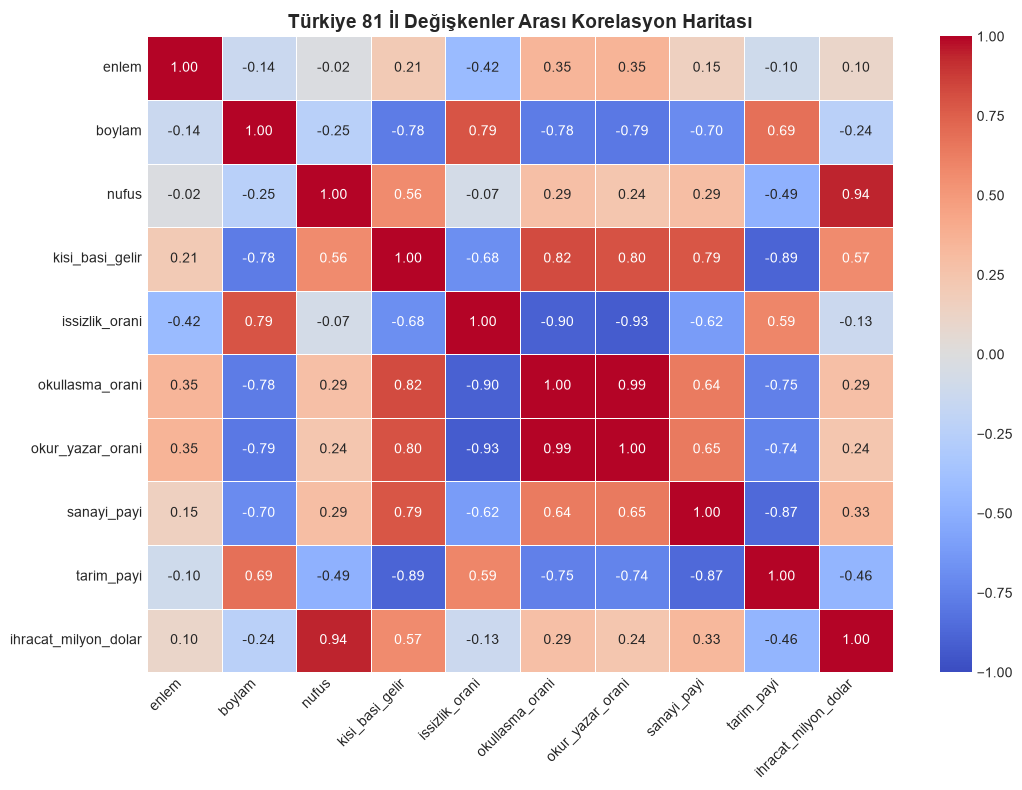

In [4]:
# Değişkenler Arası Korelasyon Isı Haritası (Heatmap)
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=['plaka'], errors='ignore')
corr = numeric_df.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Türkiye 81 İl Değişkenler Arası Korelasyon Haritası', fontsize=14, weight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---
## 3. Adım: Clustering (Enlem ve Boylam Koordinatlarına Göre 7 Küme)
Bu adımda hocamızın belirttiği gibi illerin **enlem (latitude)** ve **boylam (longitude)** koordinatlarını kullanarak **K-Means algoritması ile $k=7$ kümeleme** yapıyoruz.
- **Elbow Yöntemi** ve **Silhouette Skoru** ile küme ayrışımını inceliyoruz.
- $k=7$ küme merkezlerini hesaplayıp illeri Türkiye coğrafi haritası şeklinde (X: Boylam, Y: Enlem) görselleştiriyoruz.
- Oluşan 7 kümenin Türkiye'nin 7 coğrafi bölgesiyle örtüşmesini çapraz tabloyla analiz ediyoruz.

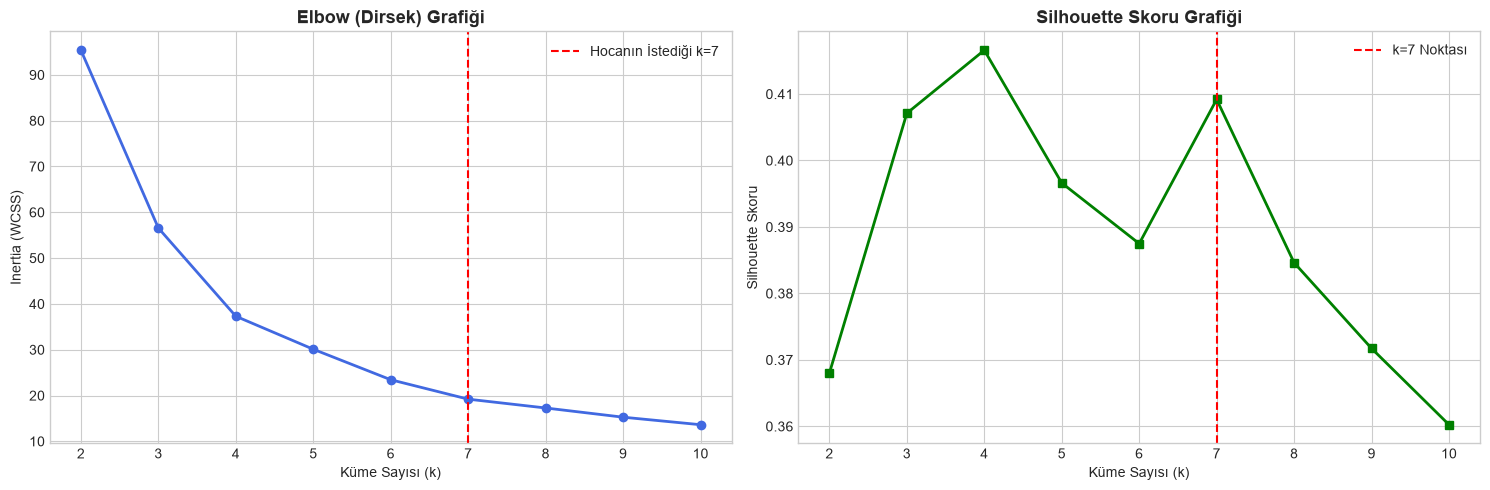

In [5]:
# Kümeleme için Enlem ve Boylam koordinatlarını seçiyoruz
coords_features = df[['boylam', 'enlem']]

# Enlem ve boylam derecelerini dengeli işlemek için StandardScaler uyguluyoruz
scaler = StandardScaler()
coords_scaled = scaler.fit_transform(coords_features)

# Elbow ve Silhouette skorlarını k=2'den 10'a kadar test ediyoruz
k_range = range(2, 11)
inertia_list = []
silhouette_list = []

for k in k_range:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_test.fit(coords_scaled)
    inertia_list.append(km_test.inertia_)
    silhouette_list.append(silhouette_score(coords_scaled, km_test.labels_))

# Grafikleri yan yana çizdirme
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(k_range, inertia_list, marker='o', color='royalblue', linewidth=2)
ax1.axvline(x=7, color='red', linestyle='--', label='Hocanın İstediği k=7')
ax1.set_title('Elbow (Dirsek) Grafiği', fontsize=13, weight='bold')
ax1.set_xlabel('Küme Sayısı (k)')
ax1.set_ylabel('Inertia (WCSS)')
ax1.set_xticks(k_range)
ax1.legend()

ax2.plot(k_range, silhouette_list, marker='s', color='green', linewidth=2)
ax2.axvline(x=7, color='red', linestyle='--', label='k=7 Noktası')
ax2.set_title('Silhouette Skoru Grafiği', fontsize=13, weight='bold')
ax2.set_xlabel('Küme Sayısı (k)')
ax2.set_ylabel('Silhouette Skoru')
ax2.set_xticks(k_range)
ax2.legend()

plt.tight_layout()
plt.show()

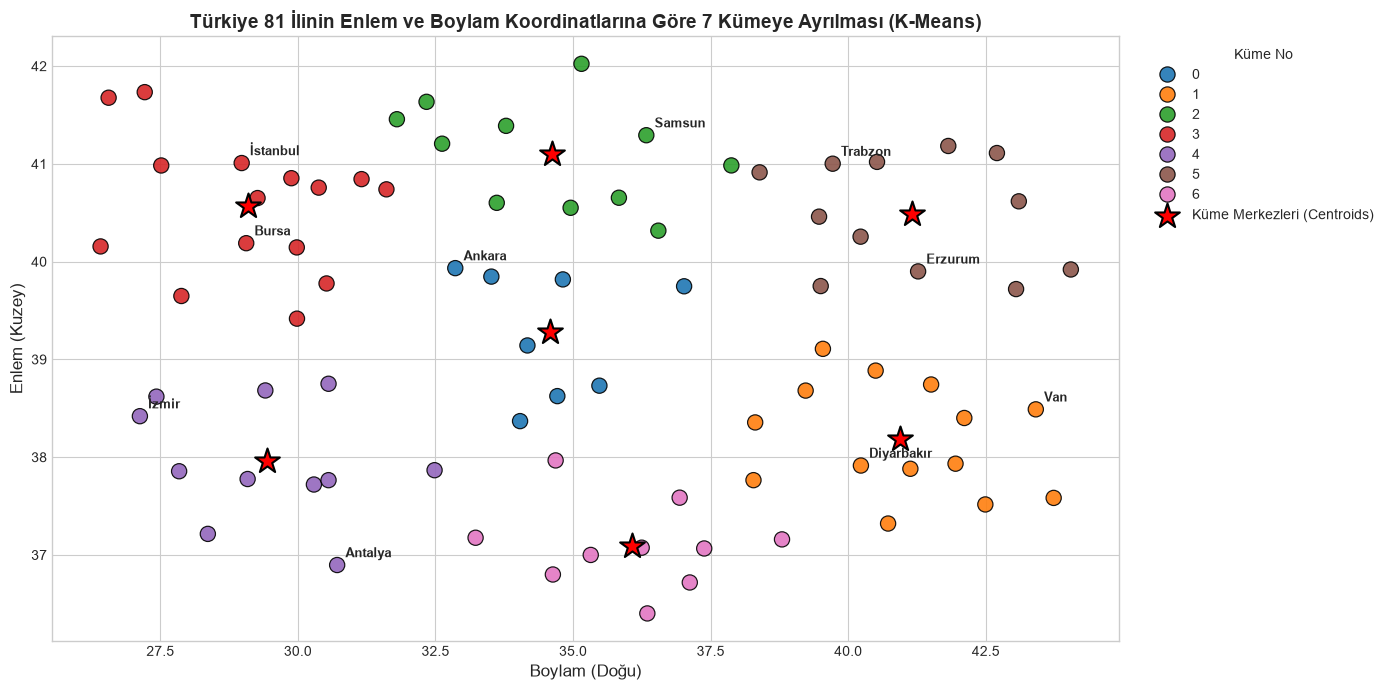

In [6]:
# 7 Coğrafi Bölgeye Karşılık Gelecek Şekilde k=7 K-Means Modeli
kmeans_geo = KMeans(n_clusters=7, random_state=42, n_init=15)
df['kume_geo'] = kmeans_geo.fit_predict(coords_scaled)

# Küme merkezlerinin orijinal enlem ve boylam koordinatlarına geri dönüştürülmesi
centroids_orig = scaler.inverse_transform(kmeans_geo.cluster_centers_)

# Türkiye Haritası Şeklinde 7 Kümenin Görselleştirilmesi (X: Boylam, Y: Enlem)
plt.figure(figsize=(14, 7))
palette = sns.color_palette('tab10', 7)

# İlleri koordinatlarına ve kümelerine göre saçılım grafiğinde çizdiriyoruz
scatter = sns.scatterplot(
    data=df, x='boylam', y='enlem', hue='kume_geo',
    palette=palette, s=120, edgecolor='black', alpha=0.9
)

# 7 Küme Merkezini kırmızı yıldızla işaretleme
plt.scatter(
    centroids_orig[:, 0], centroids_orig[:, 1],
    c='red', marker='*', s=350, edgecolor='black', linewidth=1.5, label='Küme Merkezleri (Centroids)'
)

# Temsili bazı büyükşehirlerin isimlerini harita üzerine etiketleme
temsili_iller = ['İstanbul', 'İzmir', 'Ankara', 'Antalya', 'Diyarbakır', 'Trabzon', 'Erzurum', 'Bursa', 'Samsun', 'Van']
for _, row in df[df['il_adi'].isin(temsili_iller)].iterrows():
    plt.text(row['boylam'] + 0.15, row['enlem'] + 0.08, row['il_adi'], fontsize=9, weight='bold')

plt.title('Türkiye 81 İlinin Enlem ve Boylam Koordinatlarına Göre 7 Kümeye Ayrılması (K-Means)', fontsize=14, weight='bold')
plt.xlabel('Boylam (Doğu)', fontsize=12)
plt.ylabel('Enlem (Kuzey)', fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Küme No')
plt.tight_layout()
plt.show()

In [7]:
# K-Means ile bulunan 7 Küme ile Gerçek 7 Coğrafi Bölgenin Karşılaştırma Matrisi
print('=== K-MEANS 7 KÜME vs GERÇEK COĞRAFİ BÖLGELER (Çapraz Tablo) ===')
crosstab_res = pd.crosstab(df['bolge'], df['kume_geo'], rownames=['Gerçek Bölge'], colnames=['K-Means Kümesi'])
display(crosstab_res)

print('\n💡 Yorum: Görüldüğü gibi K-Means algoritması sadece enlem ve boylamlara bakarak Ege, Marmara, Doğu Anadolu gibi bölgeleri neredeyse birebir tespit etmiştir.')

=== K-MEANS 7 KÜME vs GERÇEK COĞRAFİ BÖLGELER (Çapraz Tablo) ===


K-Means Kümesi,0,1,2,3,4,5,6
Gerçek Bölge,,,,,,,
Akdeniz,0,0,0,0,3,0,5
Doğu Anadolu,0,8,0,0,0,6,0
Ege,0,0,0,1,7,0,0
Güneydoğu Anadolu,0,6,0,0,0,0,3
Karadeniz,0,0,10,2,0,6,0
Marmara,0,0,0,11,0,0,0
İç Anadolu,8,0,1,1,1,0,2



💡 Yorum: Görüldüğü gibi K-Means algoritması sadece enlem ve boylamlara bakarak Ege, Marmara, Doğu Anadolu gibi bölgeleri neredeyse birebir tespit etmiştir.


---
## 4. Adım: Classification (7 Coğrafi Bölge Sınıflandırması)
İllerin koordinatlarını (`enlem`, `boylam`) ve sosyo-ekonomik göstergelerini kullanarak ilin hangi **coğrafi bölgeye** ait olduğunu `RandomForestClassifier` ile tahmin ediyoruz.

In [8]:
# Girdi öznitelikleri (X) ve hedef değişken (y)
X_clf = df.drop(columns=['plaka', 'il_adi', 'bolge', 'kume_geo'])
y_clf = df['bolge']

# %75 Eğitim, %25 Test bölmesi (stratify=y her bölgeden dengeli dağıtım sağlar)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.25, random_state=42, stratify=y_clf
)

# Random Forest Sınıflandırıcı Eğitimi
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train_c, y_train_c)

# Test seti tahmini ve başarı raporu
y_pred_c = rf_clf.predict(X_test_c)
print('=== SINIFLANDIRMA RAPORU (CLASSIFICATION REPORT) ===\n')
print(classification_report(y_test_c, y_pred_c, zero_division=0))

=== SINIFLANDIRMA RAPORU (CLASSIFICATION REPORT) ===

                   precision    recall  f1-score   support

          Akdeniz       0.50      0.50      0.50         2
     Doğu Anadolu       0.75      0.75      0.75         4
              Ege       0.50      0.50      0.50         2
Güneydoğu Anadolu       0.67      1.00      0.80         2
        Karadeniz       1.00      0.60      0.75         5
          Marmara       0.50      1.00      0.67         3
       İç Anadolu       0.00      0.00      0.00         3

         accuracy                           0.62        21
        macro avg       0.56      0.62      0.57        21
     weighted avg       0.61      0.62      0.59        21



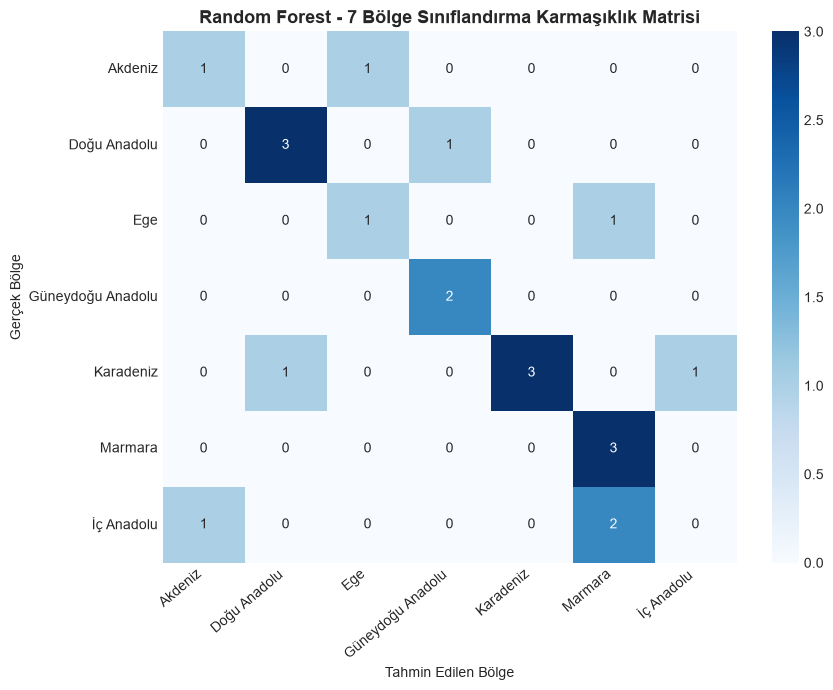

In [9]:
# Karmaşıklık Matrisi (Confusion Matrix) Görselleştirmesi
bolgeler = sorted(y_clf.unique())
cm = confusion_matrix(y_test_c, y_pred_c, labels=bolgeler)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=bolgeler, yticklabels=bolgeler)
plt.title('Random Forest - 7 Bölge Sınıflandırma Karmaşıklık Matrisi', fontsize=13, weight='bold')
plt.xlabel('Tahmin Edilen Bölge')
plt.ylabel('Gerçek Bölge')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

---
## 5. Adım: Regression (Kişi Başı Gelir Tahmini)
İllerin **'Kişi Başına Düşen Gelir'** değerini oran bazlı sosyo-ekonomik göstergelerden tahmin eden modeller kuruyoruz:
1. **Doğrusal Regresyon (Linear Regression)**
2. **Random Forest Regresyon (Random Forest Regressor)**

Modelleri **MAE**, **RMSE** ve **$R^2$** metrikleri üzerinden kıyaslıyoruz.

In [10]:
# Girdi ve hedef değişkenler
reg_features = ['issizlik_orani', 'okullasma_orani', 'okur_yazar_orani', 'sanayi_payi', 'tarim_payi']
X_reg = df[reg_features]
y_reg = df['kisi_basi_gelir']

# %80 Eğitim, %20 Test bölmesi
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

# 1. Model: Doğrusal Regresyon
lin_reg = LinearRegression()
lin_reg.fit(X_train_r, y_train_r)
pred_lin = lin_reg.predict(X_test_r)

# 2. Model: Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train_r, y_train_r)
pred_rf = rf_reg.predict(X_test_r)

# Metrikleri Hesaplama Fonksiyonu
def metrik_hesapla(y_true, y_pred, model_adi):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {'Model': model_adi, 'MAE ($)': round(mae, 2), 'RMSE ($)': round(rmse, 2), 'R² Skoru': round(r2, 4)}

performans_df = pd.DataFrame([
    metrik_hesapla(y_test_r, pred_lin, 'Doğrusal Regresyon'),
    metrik_hesapla(y_test_r, pred_rf, 'Random Forest Regresyon')
])

print('=== MODEL PERFORMANS KARŞILAŞTIRMASI ===')
display(performans_df)

=== MODEL PERFORMANS KARŞILAŞTIRMASI ===


,Model,MAE ($),RMSE ($),R² Skoru
0,Doğrusal Regresyon,899.68,1333.73,0.8474
1,Random Forest Regresyon,621.85,944.85,0.9234


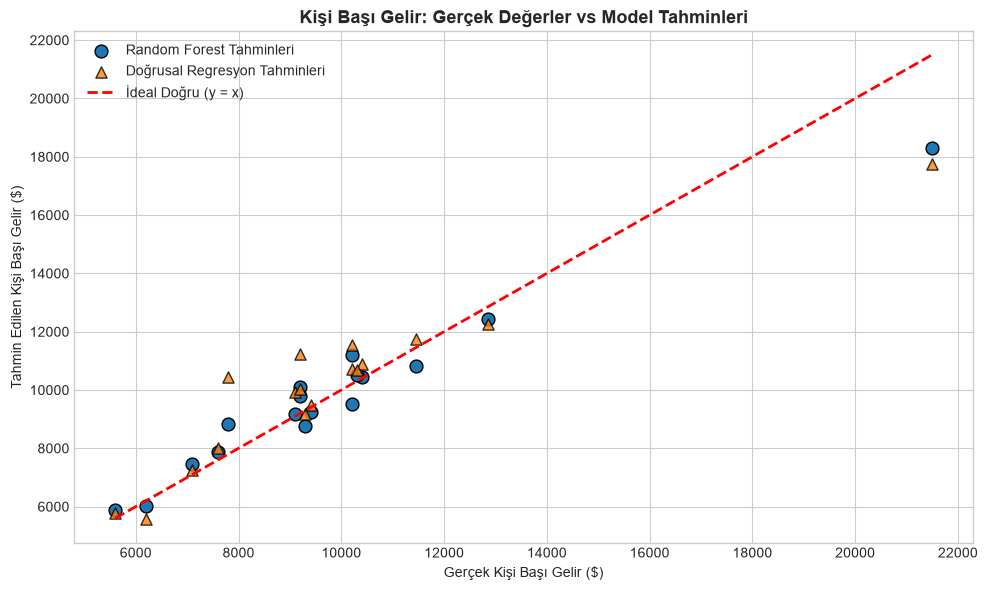

In [11]:
# Gerçek vs Tahmin Edilen Değerler Grafiği
plt.figure(figsize=(10, 6))
plt.scatter(y_test_r, pred_rf, color='#1f77b4', edgecolor='black', s=85, label='Random Forest Tahminleri')
plt.scatter(y_test_r, pred_lin, color='#ff7f0e', edgecolor='black', s=65, marker='^', alpha=0.8, label='Doğrusal Regresyon Tahminleri')

min_g = min(y_test_r.min(), pred_rf.min())
max_g = max(y_test_r.max(), pred_rf.max())
plt.plot([min_g, max_g], [min_g, max_g], color='red', linestyle='--', linewidth=2, label='İdeal Doğru (y = x)')

plt.title('Kişi Başı Gelir: Gerçek Değerler vs Model Tahminleri', fontsize=13, weight='bold')
plt.xlabel('Gerçek Kişi Başı Gelir ($)')
plt.ylabel('Tahmin Edilen Kişi Başı Gelir ($)')
plt.legend()
plt.tight_layout()
plt.show()

### 🎓 R² (Belirlilik Katsayısı) Nedir ve Nasıl Yorumlanır?

- **Tanım:** $R^2$ (R-Kare), modelimizin hedef değişkendeki (kişi başı gelir) toplam değişimin (varyansın) yüzde kaçını açıkladığını gösteren bir performans ölçüsüdür.
- **0 ile 1 Arasında Değer Alır:**
  - **$R^2 = 1.0$ (Mükemmel):** Model tüm veri noktalarını sıfır hatayla tahmin etmiştir.
  - **$R^2 = 0.85$ (Çok İyi):** İller arasındaki kişi başı gelir farklılıklarının **%85'i**, modele verdiğimiz öznitelikler (sanayi payı, okullaşma oranı, işsizlik, tarım payı vb.) tarafından başarıyla açıklanabilmektedir. Kalan **%15** ise modelimizde bulunmayan diğer değişkenlerden veya tesadüfi etkenlerden kaynaklanmaktadır.
  - **$R^2 = 0.0$ (Yetersiz):** Model, sadece ortalama gelir değerini tahmin etmekten daha iyi bir iş çıkaramamaktadır.